# 00 · Data & the map of LLM architectures

This repo walks through **every major family of language-model architecture** with small, runnable PyTorch
implementations. All notebooks share the same cached datasets (built by `scripts/prepare_data.py`) so results
are comparable.

| # | Notebook | Family |
|---|----------|--------|
| 01 | decoder-only GPT | autoregressive Transformer (GPT-2/3 style) |
| 02 | encoder-only BERT | bidirectional Transformer + masked-LM |
| 03 | encoder-decoder | original Transformer / T5 / BART with cross-attention |
| 04 | LLaMA-style decoder | RMSNorm + RoPE + SwiGLU + GQA |
| 05 | attention variants | MHA, MQA, GQA, sliding window, MLA |
| 06 | positional encodings | sinusoidal, learned, RoPE, ALiBi, NoPE |
| 07 | Mixture of Experts | sparse routing (Mixtral / DeepSeek style) |
| 08 | recurrent nets | RNN, LSTM, GRU |
| 09 | state-space models | Mamba (selective SSM) |
| 10 | linear attention family | linear attention, RetNet, RWKV |
| 11 | hybrids | Jamba-style Mamba + attention + MoE |
| 12 | vision & multimodal | ViT and a LLaVA-style vision-language model |
| 13 | diffusion LMs | masked discrete diffusion (LLaDA / MDLM style) |
| 99 | comparison | all models side by side |

---

### At a glance

| | |
|---|---|
| **Family** | Overview |
| **Representative models** | all of them |
| **Core idea** | Shared datasets and a map of the architecture families covered in this repo. |
| **Compute / memory** | – |
| **Dataset** | tiny-Shakespeare, synthetic seq2seq, sklearn digits |
| **Runtime** | ≈ 5 s on a laptop CPU |

### What you will learn

- Understand the three datasets reused by every notebook
- See how the architecture families relate (token mixer, cost, inference memory)

### Contents

1. [Text corpus: Tiny Shakespeare](#1-%C2%B7-Text-corpus%3A-Tiny-Shakespeare)
2. [Seq2seq task (for encoder-decoder models)](#2-%C2%B7-Seq2seq-task-%28for-encoder-decoder-models%29)
3. [Images (for ViT / multimodal)](#3-%C2%B7-Images-%28for-ViT-/-multimodal%29)
4. [A taxonomy of architectures (what differs, and why it matters)](#4-%C2%B7-A-taxonomy-of-architectures-%28what-differs%2C-and-why-it-matters%29)

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import json, collections
import torch, matplotlib.pyplot as plt, numpy as np, pandas as pd
import llmarch
llmarch.setup_style()
from llmarch import load_text_data, load_seq2seq_data, load_digits_data
from llmarch.data import data_card
print(json.dumps(data_card(), indent=2))

{
  "shakespeare": {
    "chars": 1115394,
    "char_vocab": 65,
    "bpe_tokens": 575809,
    "bpe_vocab": 512
  },
  "seq2seq": {
    "pairs": 6000,
    "vocab": 29,
    "max_len": 10
  },
  "digits": {
    "images": 1797,
    "size": "8x8",
    "classes": 10
  }
}


## 1 · Text corpus: Tiny Shakespeare
~1.1 M characters. We use it two ways: **character level** (65 symbols, simplest to reason about) and
**byte-level BPE** with a 512-token vocabulary trained here.

In [2]:
ch, bpe = load_text_data("char"), load_text_data("bpe")
print("char vocab:", ch["vocab_size"], "| train/val tokens:", len(ch["train"]), len(ch["val"]))
print("bpe  vocab:", bpe["vocab_size"], "| train/val tokens:", len(bpe["train"]), len(bpe["val"]))
print("\nsample (char):\n", ch["decode"](ch["train"][:200]))
print("\nsample (bpe tokens):", [bpe["itos"][i] for i in bpe["train"][:20]])

char vocab: 65 | train/val tokens: 1003854 111540
bpe  vocab: 512 | train/val tokens: 518228 57581

sample (char):
 First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you

sample (bpe tokens): ['F', 'ir', 'st', 'ĠC', 'it', 'i', 'z', 'en', ':', 'Ċ', 'B', 'e', 'f', 'ore', 'Ġwe', 'Ġp', 'ro', 'ce', 'ed', 'Ġan']


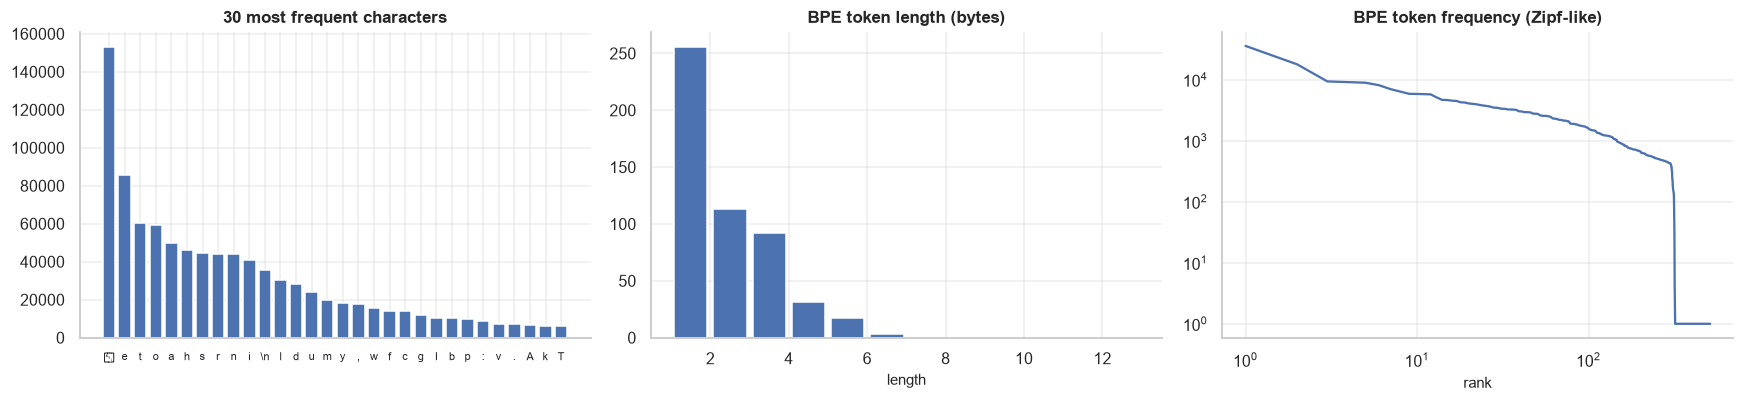

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
cnt = collections.Counter(ch["train"].tolist()); items = cnt.most_common(30)
ax[0].bar([ch["itos"][i].replace("\n", "\\n").replace(" ", "␣") for i, _ in items], [c for _, c in items])
ax[0].set_title("30 most frequent characters"); ax[0].tick_params(axis="x", labelsize=7)
lens = [len(t) for t in bpe["itos"]]; ax[1].hist(lens, bins=range(1, 14), rwidth=.85)
ax[1].set_title("BPE token length (bytes)"); ax[1].set_xlabel("length")
bcnt = np.sort(np.bincount(bpe["train"].numpy(), minlength=512))[::-1]
ax[2].loglog(np.arange(1, 513), bcnt + 1); ax[2].set_title("BPE token frequency (Zipf-like)"); ax[2].set_xlabel("rank")
plt.tight_layout(); plt.show()

## 2 · Seq2seq task (for encoder-decoder models)
Reverse a random word of 3–8 letters, e.g. `abcde<eos>` → `<bos>edcba<eos>`. It cannot be solved without looking at
the *input*, so it is the cleanest way to see **cross-attention** at work.

In [4]:
s2s = load_seq2seq_data(); itos = s2s["itos"]
src, tgt = s2s["train"]
for i in range(5):
    print("".join(itos[t] if t else "·" for t in src[i]), "->", "".join(itos[t] if t else "·" for t in tgt[i]))

ynbiqp<eos>··· -> <bos>pqibny<eos>··
zjplsg<eos>··· -> <bos>gslpjz<eos>··
ejeydtz<eos>·· -> <bos>ztdyeje<eos>·
rwzte<eos>···· -> <bos>etzwr<eos>···
dxcvk<eos>···· -> <bos>kvcxd<eos>···


## 3 · Images (for ViT / multimodal)
scikit-learn's 8×8 handwritten digits (1 797 images) — tiny but a real image-classification problem.

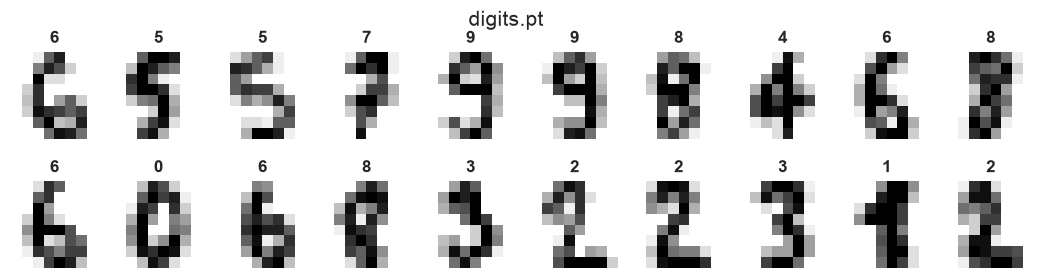

In [5]:
dg = load_digits_data()
fig, axs = plt.subplots(2, 10, figsize=(12, 2.8))
for a, x, y in zip(axs.flat, dg["x_train"][:20], dg["y_train"][:20]):
    a.imshow(x, cmap="gray_r"); a.set_title(int(y)); a.axis("off")
plt.suptitle("digits.pt"); plt.show()

## 4 · A taxonomy of architectures (what differs, and why it matters)

In [6]:
tax = pd.DataFrame([
 ["Decoder-only Transformer", "causal self-attn", "O(T²)", "KV cache grows with T", "GPT, LLaMA, Qwen, Mistral"],
 ["Encoder-only Transformer", "bidirectional self-attn", "O(T²)", "n/a (no generation)", "BERT, RoBERTa, DeBERTa"],
 ["Encoder-decoder", "self + cross-attn", "O(T²)", "KV cache + encoder memory", "T5, BART, Whisper"],
 ["Mixture of Experts", "attn + sparse FFN", "O(T²), sparse FLOPs", "same as dense", "Mixtral, DeepSeek-V3, Qwen-MoE"],
 ["Recurrent (RNN/LSTM/GRU)", "recurrence", "O(T)", "constant state", "ELMo, classic LMs"],
 ["State-space (SSM)", "selective scan", "O(T)", "constant state", "Mamba, S4, Mamba-2"],
 ["Linear-attn / retention / RWKV", "decayed recurrence", "O(T)", "constant state", "RetNet, RWKV, GLA"],
 ["Hybrid", "SSM + attn (+MoE)", "mostly O(T)", "small KV cache", "Jamba, Zamba, Samba"],
 ["Vision / multimodal", "patches → tokens", "O(P²)", "prefix tokens", "ViT, LLaVA, CLIP"],
 ["Diffusion LM", "bidirectional denoiser", "O(T²·steps)", "none", "LLaDA, MDLM, Dream"],
], columns=["family", "token mixer", "train-time cost", "inference memory", "examples"])
tax

,family,token mixer,train-time cost,inference memory,examples
0,Decoder-only Transformer,causal self-attn,O(T²),KV cache grows with T,"GPT, LLaMA, Qwen, Mistral"
1,Encoder-only Transformer,bidirectional self-attn,O(T²),n/a (no generation),"BERT, RoBERTa, DeBERTa"
2,Encoder-decoder,self + cross-attn,O(T²),KV cache + encoder memory,"T5, BART, Whisper"
3,Mixture of Experts,attn + sparse FFN,"O(T²), sparse FLOPs",same as dense,"Mixtral, DeepSeek-V3, Qwen-MoE"
4,Recurrent (RNN/LSTM/GRU),recurrence,O(T),constant state,"ELMo, classic LMs"
5,State-space (SSM),selective scan,O(T),constant state,"Mamba, S4, Mamba-2"
6,Linear-attn / retention / RWKV,decayed recurrence,O(T),constant state,"RetNet, RWKV, GLA"
7,Hybrid,SSM + attn (+MoE),mostly O(T),small KV cache,"Jamba, Zamba, Samba"
8,Vision / multimodal,patches → tokens,O(P²),prefix tokens,"ViT, LLaVA, CLIP"
9,Diffusion LM,bidirectional denoiser,O(T²·steps),none,"LLaDA, MDLM, Dream"


---

## Key takeaways

- Every notebook trains on the same cached data, so results are comparable.
- Architectures differ mainly in their **token mixer** (attention, recurrence, SSM, …) and in the resulting compute / memory profile.

---
*next: `01_decoder_only_gpt` →*